<a href="https://colab.research.google.com/github/akhil7102004-coder/Census-Income-Segmentation-Unsupervised-Learning-/blob/main/Census_Income_Segmentation_%E2%80%93_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
adult = pd.read_csv("/content/adult_dataset.csv")
adult.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [ ]:
adult.shape

(48842, 15)

In [ ]:
adult.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [ ]:
adult.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [ ]:
adult.describe(include='object')

,workclass,education,marital-status,occupation,relationship,race,sex,native-country,income
count,45480,48842,48842,45485,48842,48842,48842,46137,48842
unique,9,16,7,15,6,5,2,42,4
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,32220,15784,22379,5854,19716,41762,32650,41622,24720


##DATA PREPROCESSING

In [ ]:
adult.duplicated().sum()

np.int64(16)

In [ ]:
adult.drop_duplicates(inplace = True)
adult.reset_index(drop = True,inplace = True)
adult.shape

(48826, 15)

In [ ]:
adult.isnull().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [ ]:
(adult == '?').sum()

,0
age,0
workclass,1763
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1758
relationship,0
race,0
sex,0


In [ ]:
adult.replace('?',np.nan, inplace = True)

In [ ]:
num_cols = adult.select_dtypes(include=np.number).columns
cat_cols = adult.select_dtypes(include='object').columns

for col in num_cols:
    adult[col] = adult[col].fillna(adult[col].median())

for col in cat_cols:
    adult[col] = adult[col].fillna(adult[col].mode()[0])

print("Total missing values:", adult.isnull().sum().sum())

Total missing values: 0


In [ ]:
num_cols

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [ ]:
adult.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


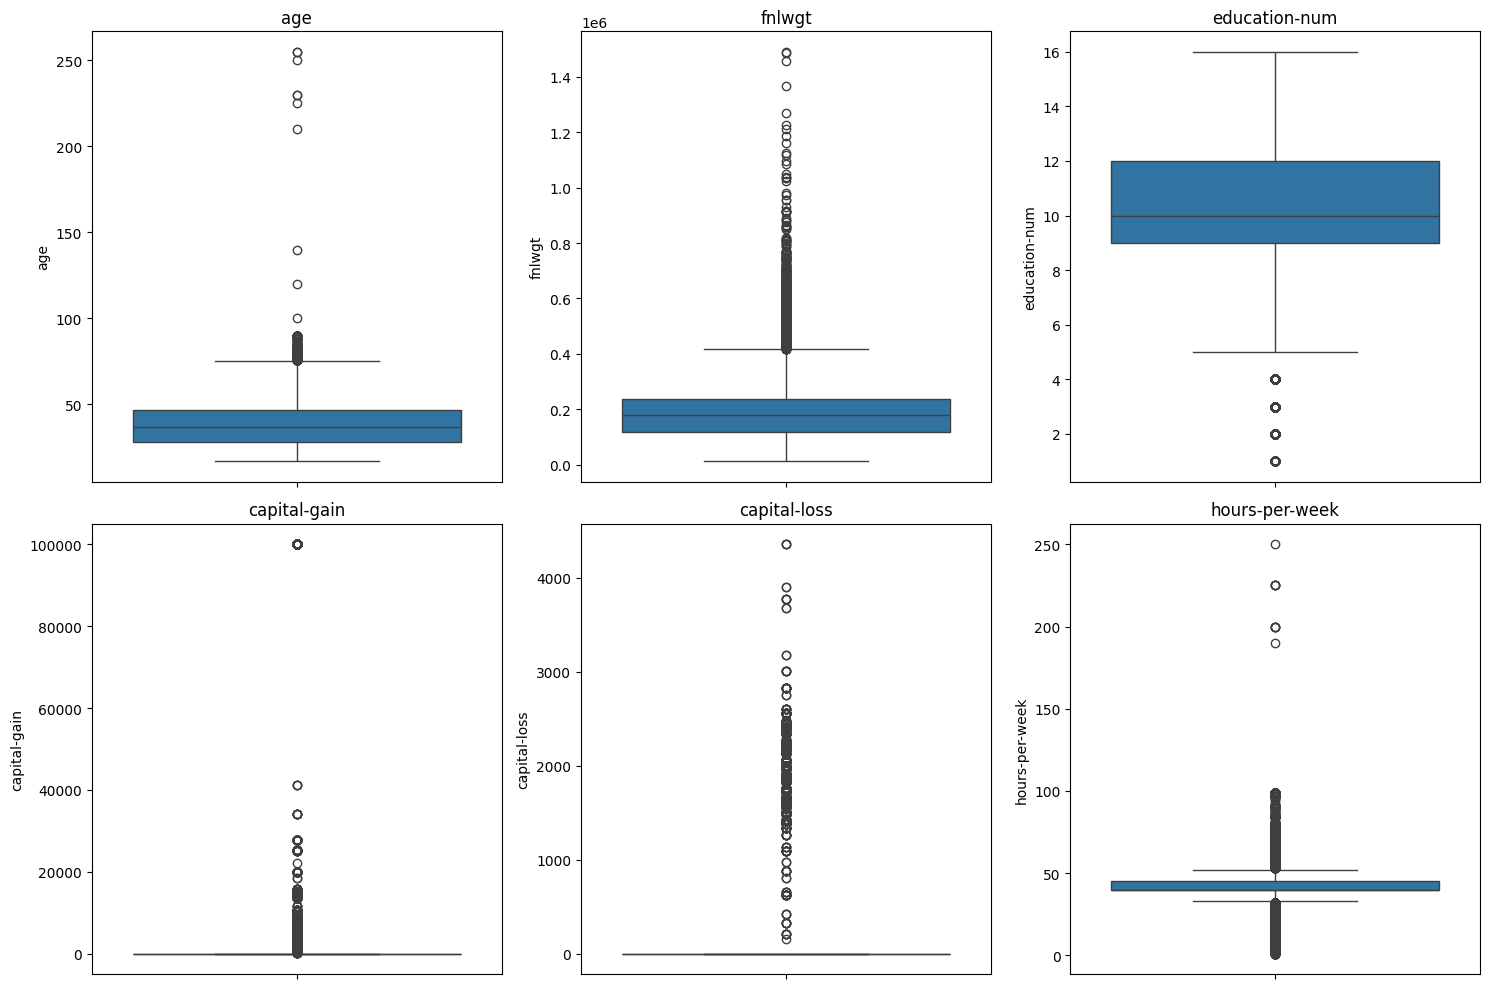

In [ ]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=adult[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
for col in num_cols:
    Q1 = adult[col].quantile(0.25)
    Q3 = adult[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((adult[col] < lower_bound) | (adult[col] > upper_bound)).sum()

    print(f"{col}: {outlier_count} outliers")

age: 363 outliers
fnlwgt: 1453 outliers
education-num: 1792 outliers
capital-gain: 4035 outliers
capital-loss: 2282 outliers
hours-per-week: 12833 outliers


In [ ]:
outlier_cols = ['age', 'fnlwgt', 'hours-per-week']

for col in outlier_cols:
    Q1 = adult[col].quantile(0.25)
    Q3 = adult[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    adult[col] = adult[col].clip(lower_bound, upper_bound)

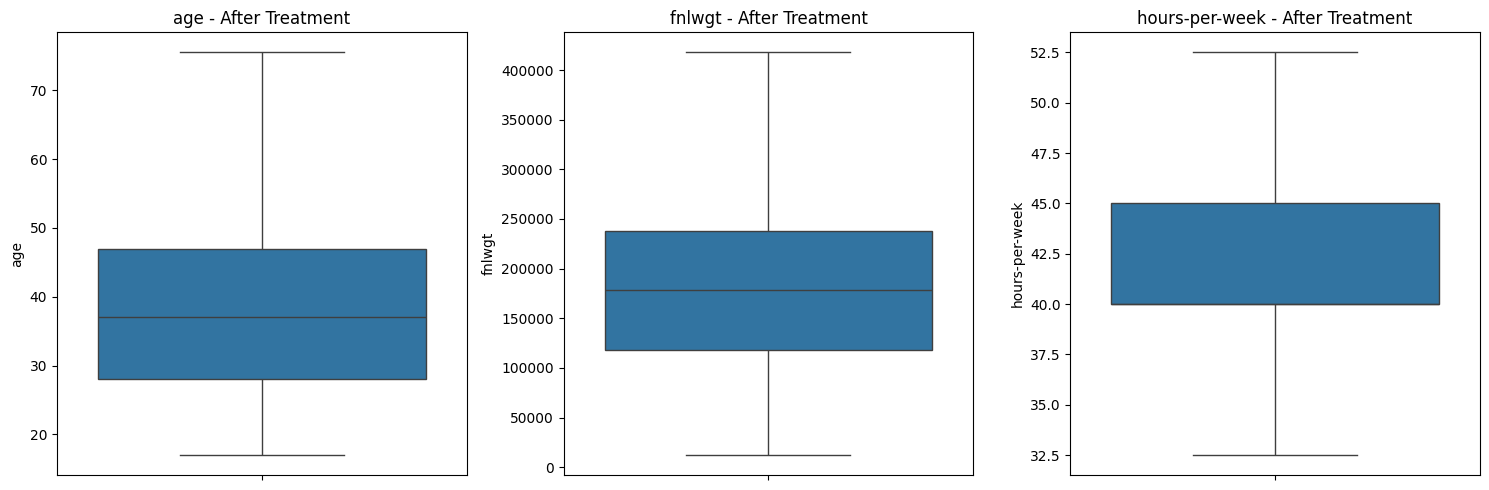

In [ ]:
plt.figure(figsize=(15, 5))

for i, col in enumerate(outlier_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=adult[col])
    plt.title(f'{col} - After Treatment')

plt.tight_layout()
plt.show()

In [ ]:
adult.shape

(48826, 15)

ENCODING

In [ ]:
income = adult['income'].copy()
X = adult.drop('income', axis=1)

In [ ]:
categorical_cols = X.select_dtypes(include='object').columns

print(categorical_cols)

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')


In [ ]:
X_encoded = pd.get_dummies(X,columns=categorical_cols,drop_first=True,dtype=int)

print("Before encoding:", X.shape)
print("After encoding:", X_encoded.shape)

X_encoded.head()

Before encoding: (48826, 14)
After encoding: (48826, 97)


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39.0,77516,13,2174,0,40.0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50.0,83311,13,0,0,32.5,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,38.0,215646,9,0,0,40.0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
3,53.0,234721,7,0,0,40.0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,28.0,338409,13,0,0,40.0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_encoded)

print("Shape of scaled data:", X_scaled.shape)

Shape of scaled data: (48826, 97)


In [ ]:
X_scaled = pd.DataFrame(X_scaled,columns=X_encoded.columns,index=X_encoded.index)
X_scaled.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,0.035123,-1.146152,1.136533,0.146861,-0.217164,-0.187370,-0.254632,-0.013578,-1.802003,-0.185487,...,-0.036791,-0.059975,-0.020243,-0.046644,-0.035368,-0.024378,-0.022634,0.296968,-0.041265,-0.021709
1,0.864064,-1.085355,1.136533,-0.144828,-0.217164,-1.430414,-0.254632,-0.013578,-1.802003,-0.185487,...,-0.036791,-0.059975,-0.020243,-0.046644,-0.035368,-0.024378,-0.022634,0.296968,-0.041265,-0.021709
2,-0.040236,0.303009,-0.419444,-0.144828,-0.217164,-0.187370,-0.254632,-0.013578,0.554938,-0.185487,...,-0.036791,-0.059975,-0.020243,-0.046644,-0.035368,-0.024378,-0.022634,0.296968,-0.041265,-0.021709
3,1.090139,0.503130,-1.197432,-0.144828,-0.217164,-0.187370,-0.254632,-0.013578,0.554938,-0.185487,...,-0.036791,-0.059975,-0.020243,-0.046644,-0.035368,-0.024378,-0.022634,0.296968,-0.041265,-0.021709
4,-0.793819,1.590950,1.136533,-0.144828,-0.217164,-0.187370,-0.254632,-0.013578,0.554938,-0.185487,...,-0.036791,-0.059975,-0.020243,-0.046644,-0.035368,-0.024378,-0.022634,-3.367365,-0.041265,-0.021709


##EDA

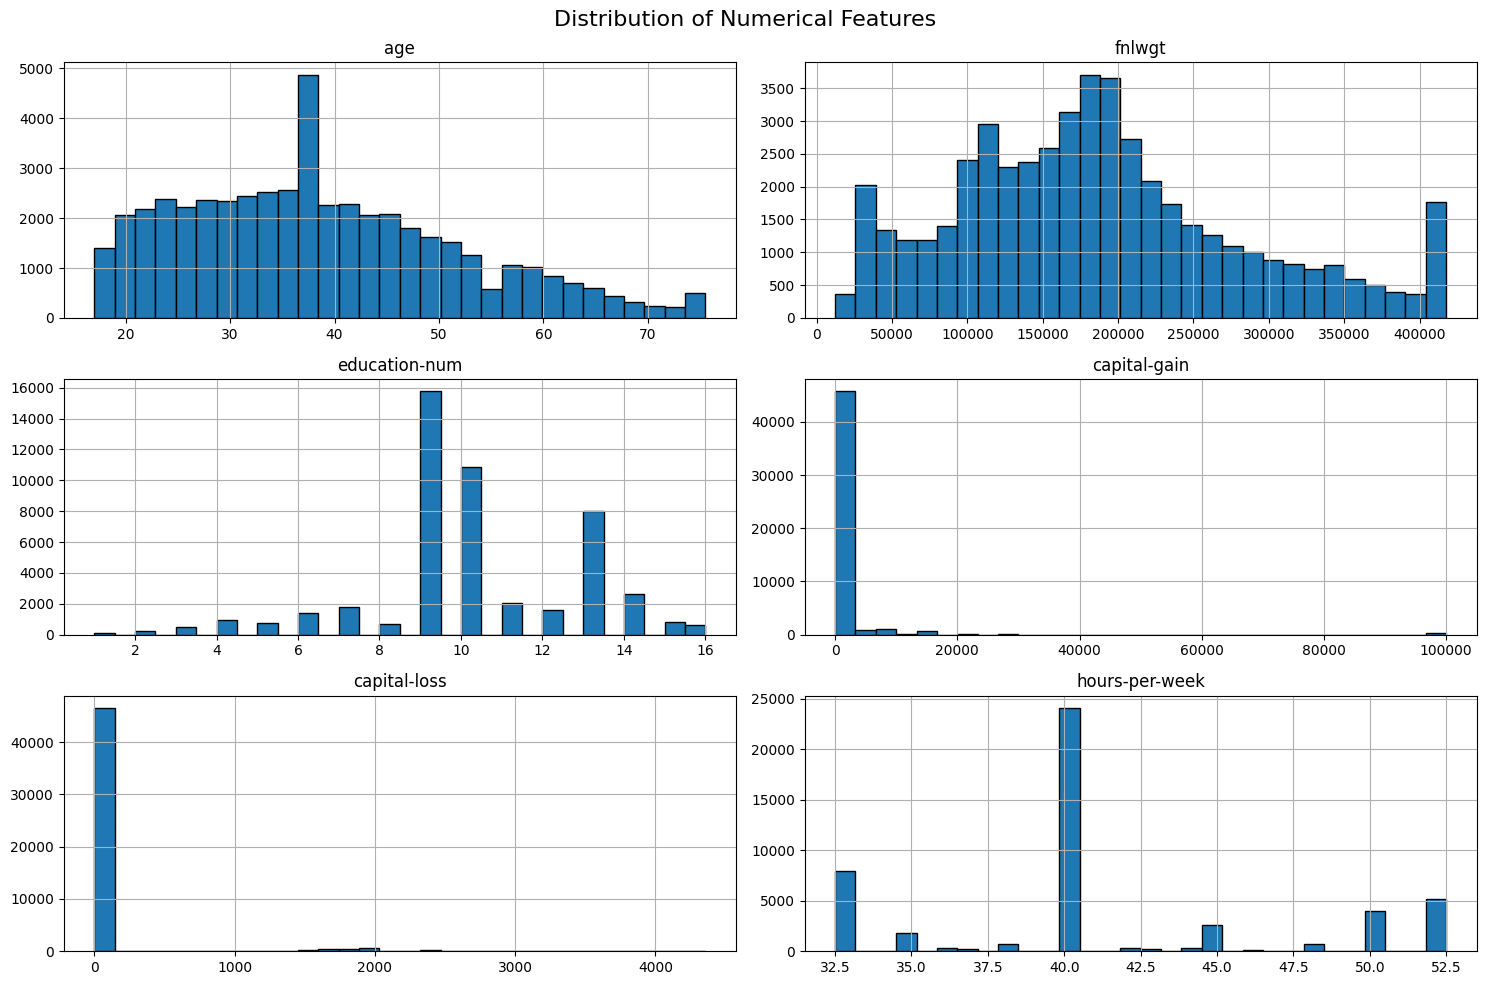

In [ ]:
adult[num_cols].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor='black')

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

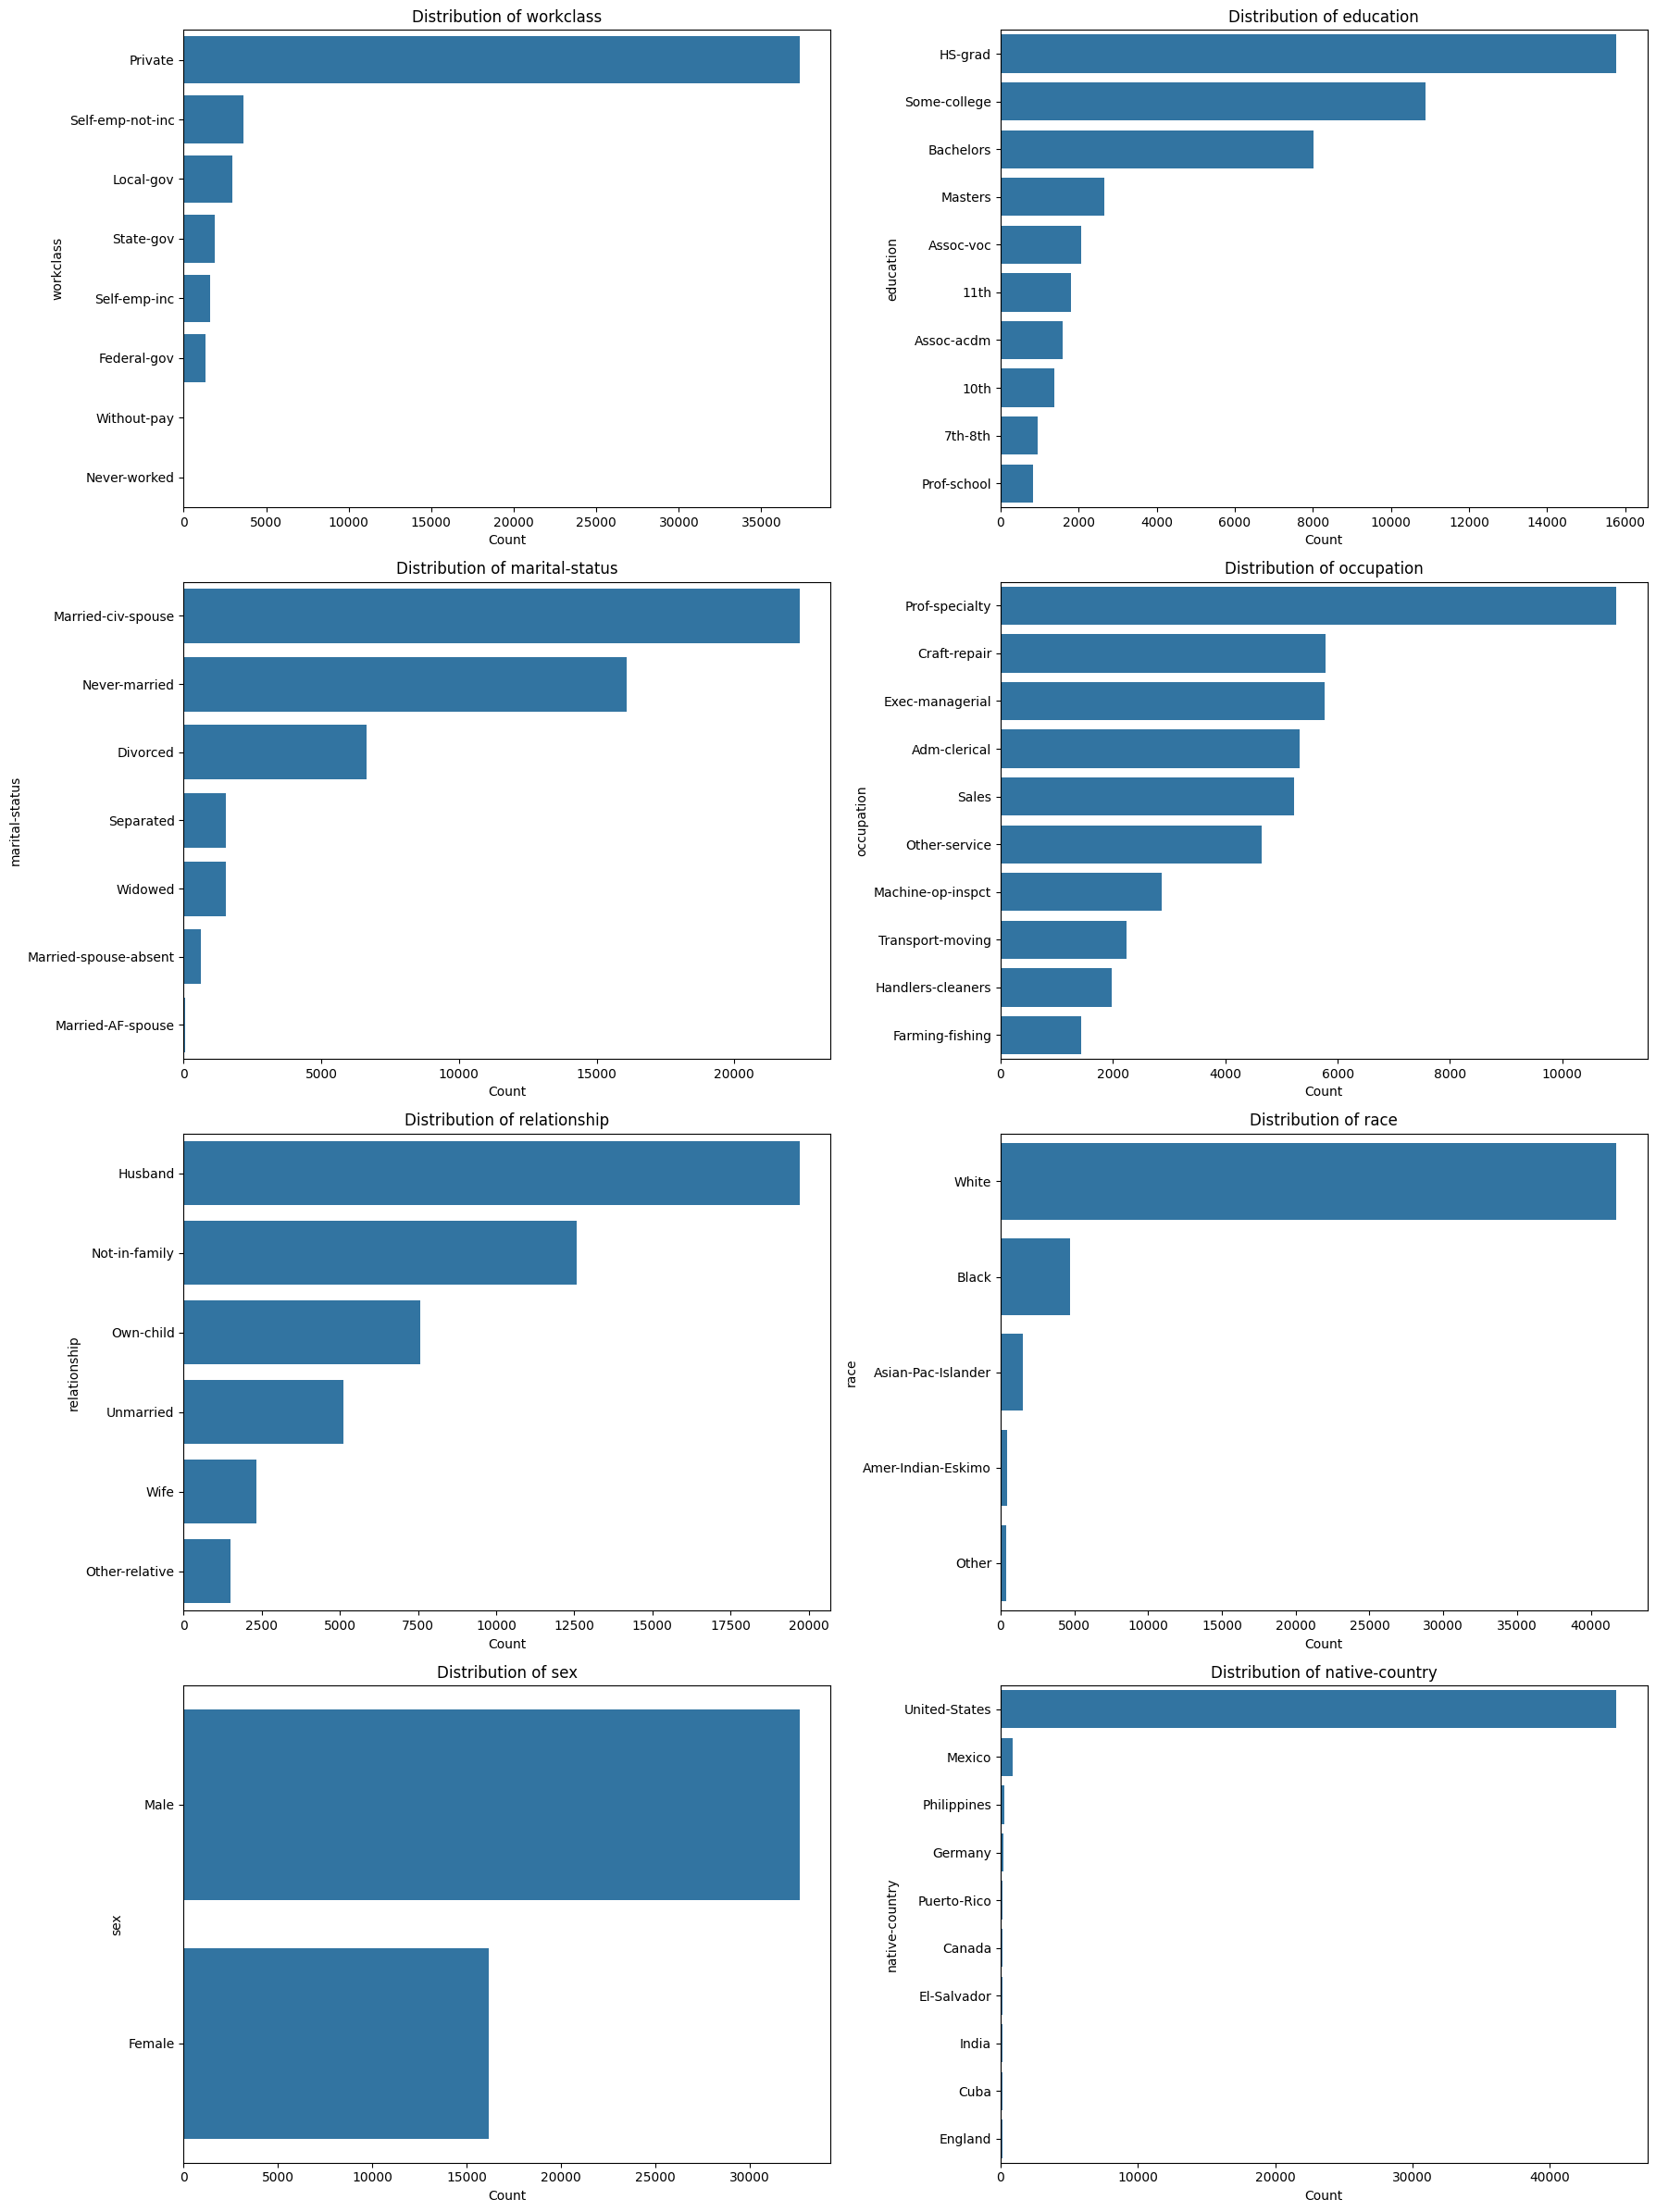

In [ ]:
cat_cols = [
    'workclass',
    'education',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native-country'
]

plt.figure(figsize=(18, 24))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(4, 2, i)

    order = adult[col].value_counts().head(10).index

    sns.countplot(data=adult[adult[col].isin(order)],y=col,order=order)

    plt.title(f'Distribution of {col}')
    plt.xlabel('Count')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

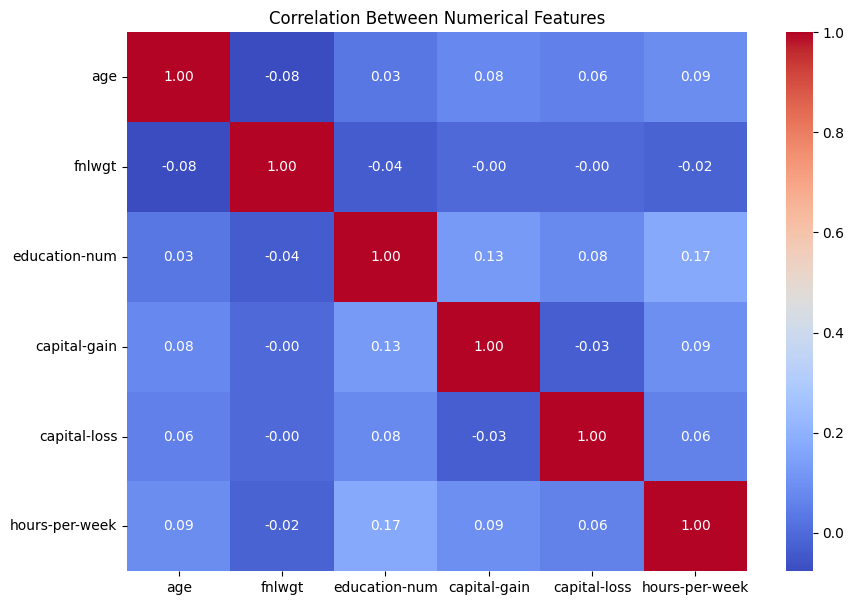

In [ ]:
num_cols = [
    'age',
    'fnlwgt',
    'education-num',
    'capital-gain',
    'capital-loss',
    'hours-per-week'
]

correlation = adult[num_cols].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')

plt.title('Correlation Between Numerical Features')
plt.show()

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [ ]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.03542646 0.02757282]

Total Explained Variance:
0.06299927531387159


In [ ]:
pca_df = pd.DataFrame(X_pca,columns=['PC1', 'PC2'],index=X_scaled.index)
pca_df.head()

,PC1,PC2
0,0.837889,2.527714
1,3.171025,0.401906
2,-0.864993,-0.409100
3,-1.209836,-1.893449
4,-0.006194,-1.113634


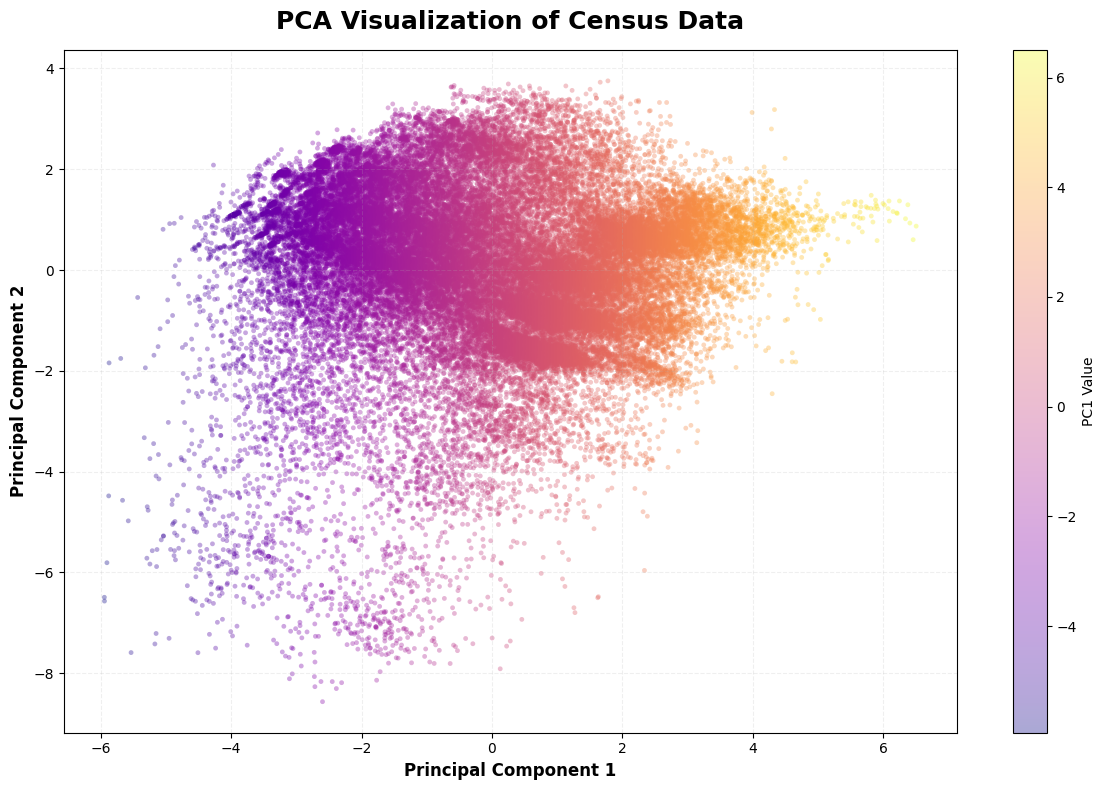

In [ ]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(pca_df['PC1'],pca_df['PC2'],c=pca_df['PC1'],cmap='plasma',s=12,alpha=0.35,edgecolors='none')

plt.colorbar(scatter,label='PC1 Value')

plt.title('PCA Visualization of Census Data',fontsize=18,fontweight='bold',pad=15)

plt.xlabel('Principal Component 1',fontsize=12,fontweight='bold')

plt.ylabel('Principal Component 2',fontsize=12,fontweight='bold')

plt.grid(alpha=0.2,linestyle='--')

plt.tight_layout()
plt.show()

### PCA Observation

PCA was used mainly to visualize the high-dimensional data in 2 dimensions.

The first two principal components explain only a small part of the total variance, so the PCA plot gives only a simplified view of the dataset.

##CLUSTERING

In [ ]:
from sklearn.cluster import KMeans

inertia = []
K = range(2, 11)

for k in K:kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

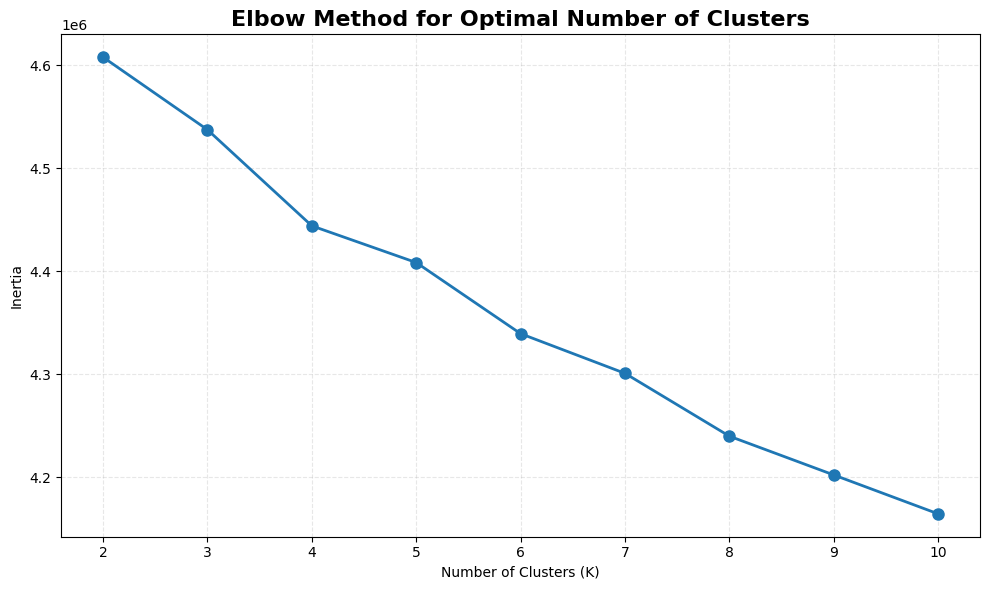

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(K,inertia,marker='o',linewidth=2,markersize=8)

plt.title('Elbow Method for Optimal Number of Clusters',fontsize=16,fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.xticks(list(K))
plt.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

##SILHOUETTE SCORE

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=10000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}: Silhouette Score = {score:.4f}")

K = 2: Silhouette Score = 0.0508
K = 3: Silhouette Score = 0.0459
K = 4: Silhouette Score = 0.0334
K = 5: Silhouette Score = 0.0307
K = 6: Silhouette Score = 0.0166
K = 7: Silhouette Score = 0.0396
K = 8: Silhouette Score = 0.0438
K = 9: Silhouette Score = 0.0253
K = 10: Silhouette Score = 0.0436


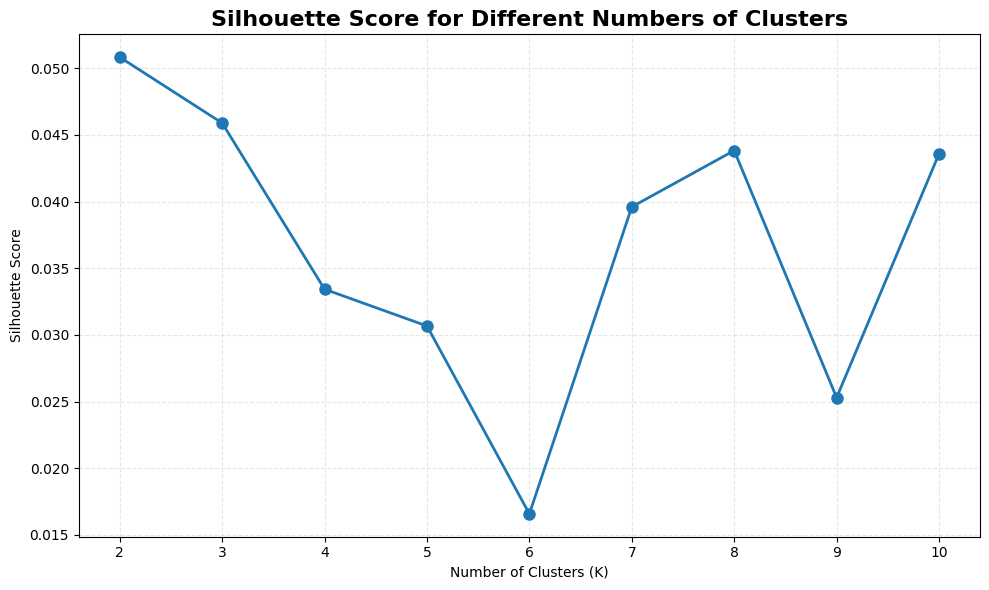

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    K,
    silhouette_scores,
    marker='o',
    linewidth=2,
    markersize=8)

plt.title(
    'Silhouette Score for Different Numbers of Clusters',
    fontsize=16,
    fontweight='bold')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.xticks(list(K))
plt.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

##K-MEAN

In [ ]:
final_kmeans = KMeans(n_clusters=2,random_state=42,n_init=10)

kmeans_labels = final_kmeans.fit_predict(X_scaled)

adult['KMeans_Cluster'] = kmeans_labels

print(adult['KMeans_Cluster'].value_counts().sort_index())

KMeans_Cluster
0    25659
1    23167
Name: count, dtype: int64


In [ ]:
pca_df['KMeans_Cluster'] = kmeans_labels

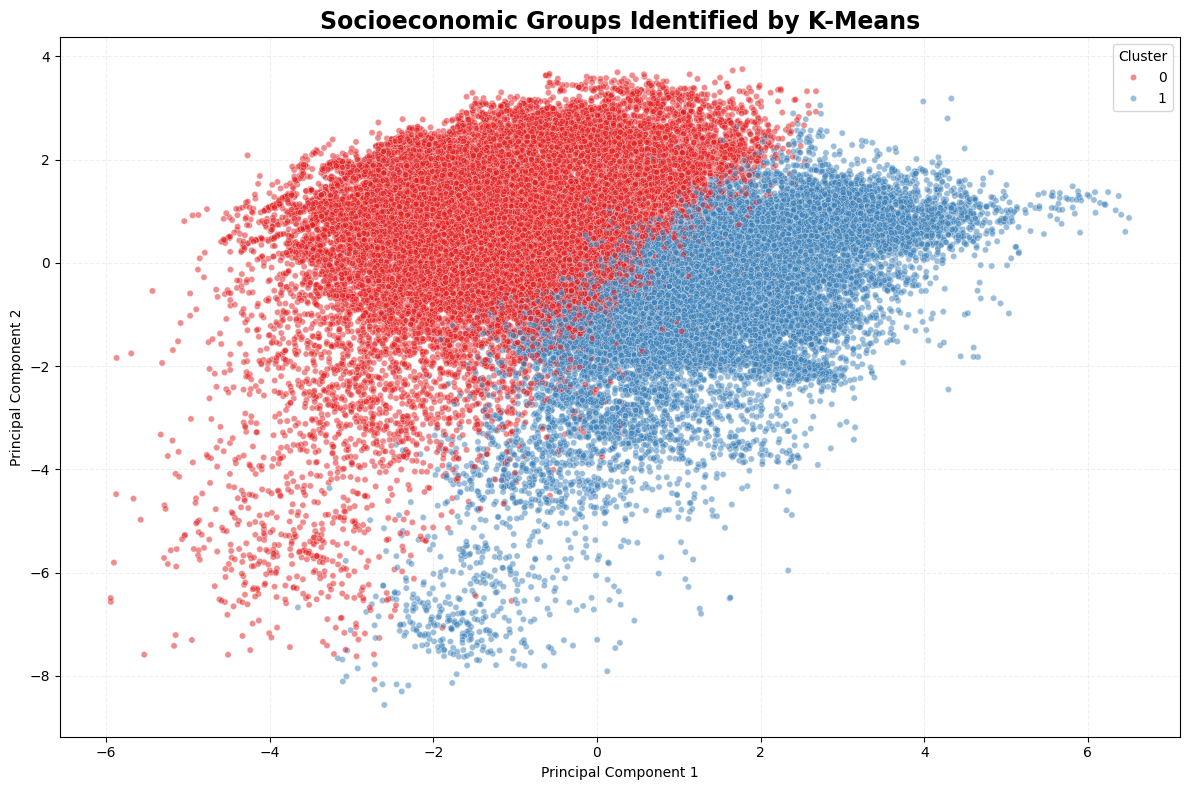

In [ ]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='KMeans_Cluster',
    palette='Set1',
    alpha=0.5,
    s=20
)

plt.title(
    'Socioeconomic Groups Identified by K-Means',
    fontsize=17,
    fontweight='bold')

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(title='Cluster',loc='best')

plt.grid(alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

##Agglomerative Clustering

In [ ]:
sample_size = 10000

X_sample = X_scaled.sample(n=sample_size,random_state=42)

print("Sample shape:", X_sample.shape)

Sample shape: (10000, 97)


In [ ]:
from sklearn.cluster import AgglomerativeClustering

agg_model = AgglomerativeClustering(n_clusters=2,linkage='ward')

agg_labels = agg_model.fit_predict(X_sample)

print("Agglomerative Clustering completed.")

Agglomerative Clustering completed.


In [ ]:
print(pd.Series(agg_labels).value_counts().sort_index())

0     966
1    9034
Name: count, dtype: int64


In [ ]:
agg_score = silhouette_score(
    X_sample,
    agg_labels,
    sample_size=5000,
    random_state=42
)

print(
    "Agglomerative Silhouette Score:",
    round(agg_score, 4)
)

Agglomerative Silhouette Score: 0.4709


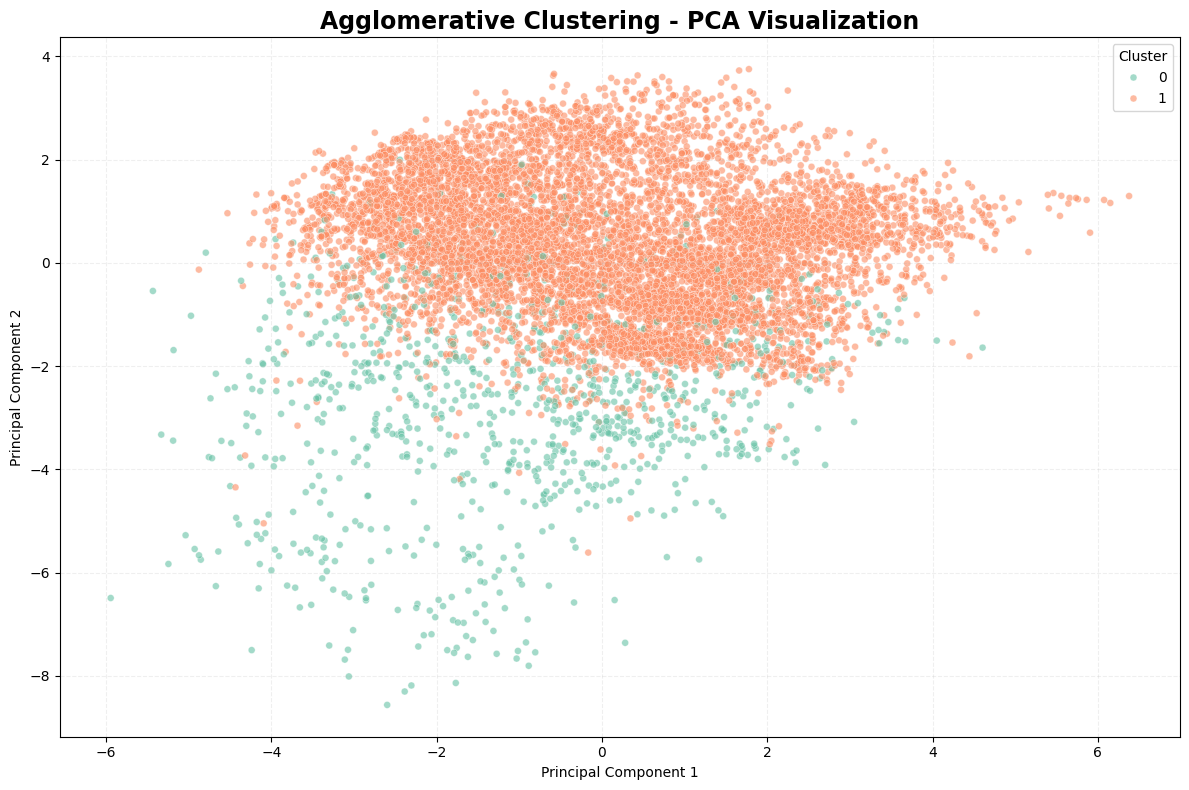

In [ ]:
agg_pca = pca_df.loc[
    X_sample.index,
    ['PC1', 'PC2']
].copy()

agg_pca['Agg_Cluster'] = agg_labels

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=agg_pca,
    x='PC1',
    y='PC2',
    hue='Agg_Cluster',
    palette='Set2',
    alpha=0.6,
    s=25
)

plt.title(
    'Agglomerative Clustering - PCA Visualization',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')

plt.grid(alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

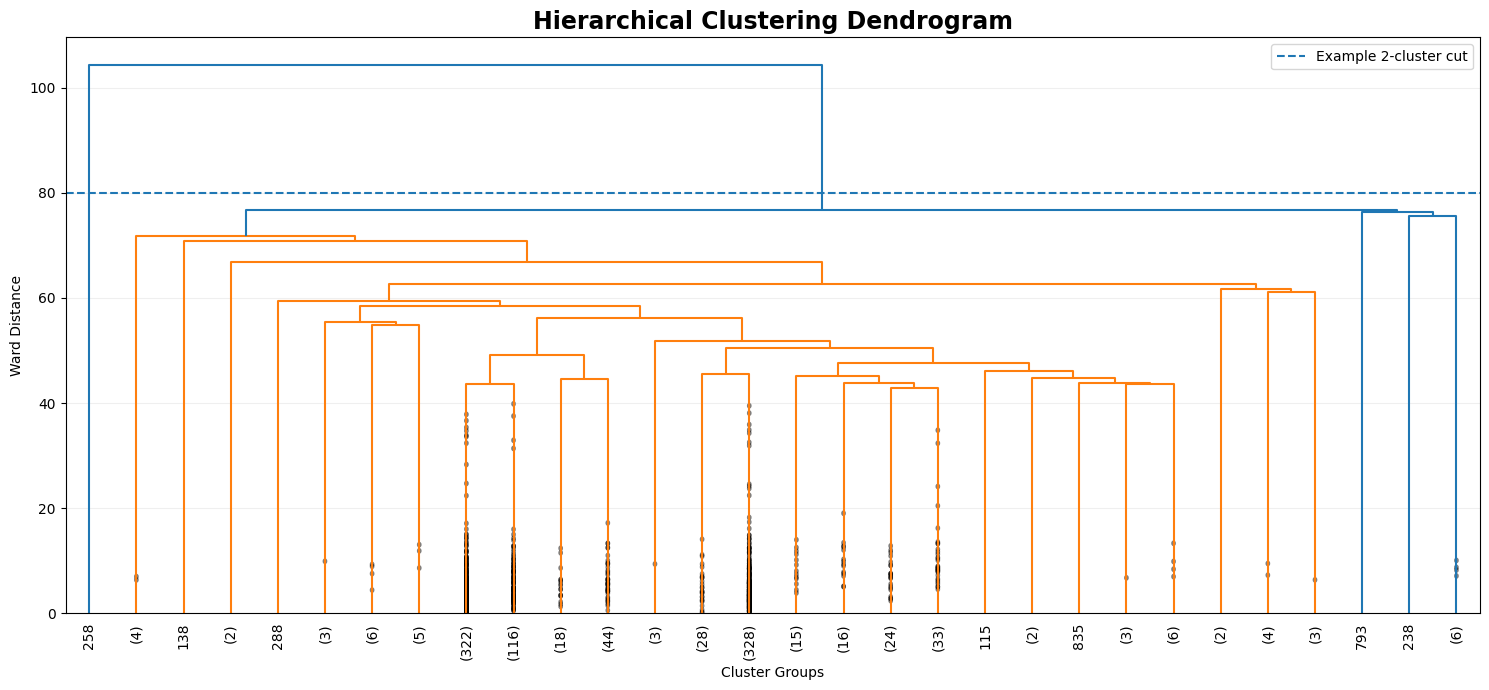

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

X_dendro = X_scaled.sample(
    n=1000,
    random_state=42
)

linked = linkage(X_dendro, method='ward')

plt.figure(figsize=(15, 7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)

plt.axhline(
    y=80,
    linestyle='--',
    label='Example 2-cluster cut'
)

plt.title(
    'Hierarchical Clustering Dendrogram',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel('Cluster Groups')
plt.ylabel('Ward Distance')
plt.legend()
plt.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

### Agglomerative Clustering

Agglomerative Clustering was also applied to compare it with K-Means.

A dendrogram was used to visualize how smaller clusters are combined step by step.

Agglomerative Clustering gave a higher Silhouette Score than K-Means, but the cluster sizes were more imbalanced.

##Fair K-Means vs Agglomerative Comparison

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_sample = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_sample_labels = kmeans_sample.fit_predict(X_sample)

kmeans_sample_score = silhouette_score(
    X_sample,
    kmeans_sample_labels,
    sample_size=5000,
    random_state=42
)

print("K-Means Silhouette Score:", round(kmeans_sample_score, 4))
print("Agglomerative Silhouette Score:", round(agg_score, 4))

K-Means Silhouette Score: 0.0507
Agglomerative Silhouette Score: 0.4709


In [ ]:
print("\nK-Means Cluster Sizes:")
print(pd.Series(kmeans_sample_labels).value_counts().sort_index())

print("\nAgglomerative Cluster Sizes:")
print(pd.Series(agg_labels).value_counts().sort_index())


K-Means Cluster Sizes:
0    5246
1    4754
Name: count, dtype: int64

Agglomerative Cluster Sizes:
0     966
1    9034
Name: count, dtype: int64


##Cluster Profiling

In [ ]:
profile = adult.groupby('KMeans_Cluster')[
    [
        'age',
        'education-num',
        'hours-per-week',
        'capital-gain',
        'capital-loss'
    ]
].mean().round(2)

profile

,age,education-num,hours-per-week,capital-gain,capital-loss
KMeans_Cluster,,,,,
0,34.24,9.82,39.61,350.48,53.46
1,43.29,10.37,42.82,1886.77,125.26


In [ ]:
categorical_profile = adult.groupby('KMeans_Cluster')[
    [
        'workclass',
        'education',
        'occupation',
        'marital-status',
        'relationship',
        'sex'
    ]
].agg(lambda x: x.mode()[0])

categorical_profile

,workclass,education,occupation,marital-status,relationship,sex
KMeans_Cluster,,,,,,
0,Private,HS-grad,Prof-specialty,Never-married,Not-in-family,Female
1,Private,HS-grad,Prof-specialty,Married-civ-spouse,Husband,Male


In [ ]:
adult['income'] = adult['income'].str.replace('.', '', regex=False).str.strip()

print(adult['income'].value_counts())

income
<=50K    37139
>50K     11687
Name: count, dtype: int64


In [ ]:
income_profile = pd.crosstab(
    adult['KMeans_Cluster'],
    adult['income'],
    normalize='index'
) * 100

income_profile.round(2)

income,<=50K,>50K
KMeans_Cluster,,
0,94.63,5.37
1,55.50,44.50


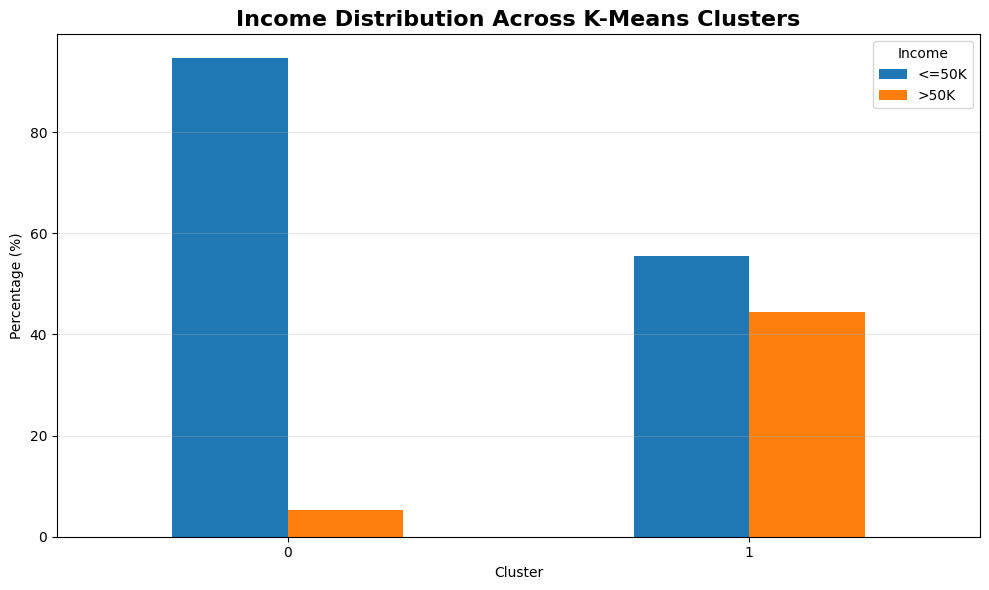

In [ ]:
income_profile.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title(
    'Income Distribution Across K-Means Clusters',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Cluster')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Income')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

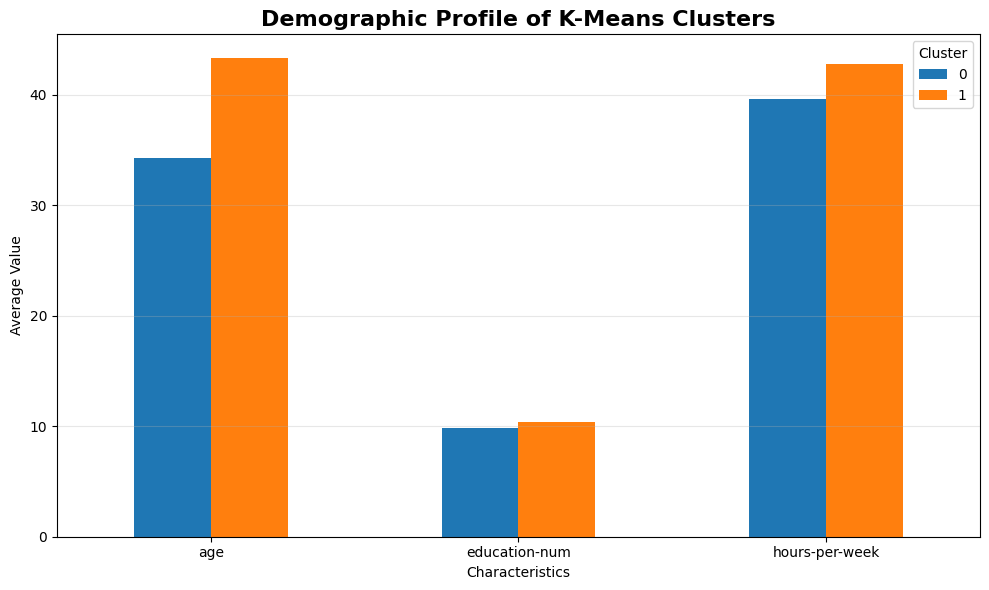

In [ ]:
cluster_means = adult.groupby('KMeans_Cluster')[
    ['age', 'education-num', 'hours-per-week']
].mean()

cluster_means.T.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title(
    'Demographic Profile of K-Means Clusters',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Characteristics')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(title='Cluster')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
cluster_summary = adult.groupby('KMeans_Cluster').agg({
    'age': 'mean',
    'education-num': 'mean',
    'hours-per-week': 'mean',
    'capital-gain': 'mean',
    'capital-loss': 'mean',
    'workclass': lambda x: x.mode()[0],
    'education': lambda x: x.mode()[0],
    'occupation': lambda x: x.mode()[0]
}).round(2)

cluster_summary

,age,education-num,hours-per-week,capital-gain,capital-loss,workclass,education,occupation
KMeans_Cluster,,,,,,,,
0,34.24,9.82,39.61,350.48,53.46,Private,HS-grad,Prof-specialty
1,43.29,10.37,42.82,1886.77,125.26,Private,HS-grad,Prof-specialty


In [ ]:
cluster_distribution = adult['KMeans_Cluster'].value_counts().sort_index()

cluster_percentage = (
    adult['KMeans_Cluster']
    .value_counts(normalize=True)
    .sort_index() * 100
).round(2)

cluster_size = pd.DataFrame({
    'Count': cluster_distribution,
    'Percentage': cluster_percentage
})

cluster_size

,Count,Percentage
KMeans_Cluster,,
0,25659,52.55
1,23167,47.45


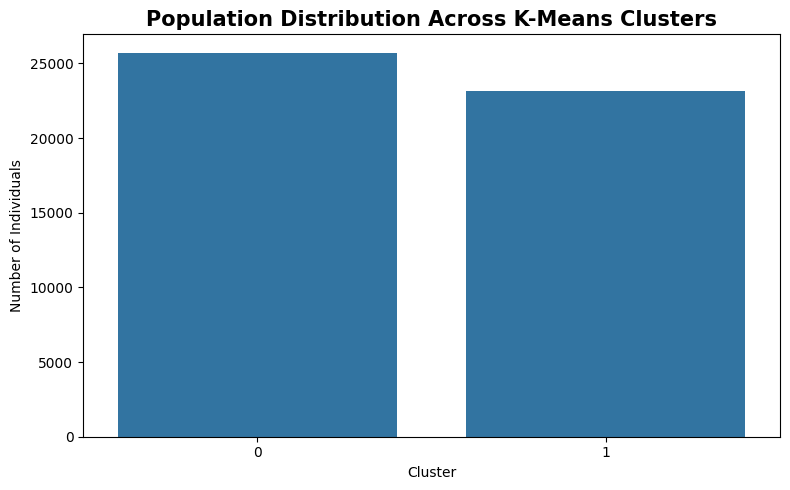

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=adult,
    x='KMeans_Cluster'
)

plt.title(
    'Population Distribution Across K-Means Clusters',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Cluster')
plt.ylabel('Number of Individuals')

plt.tight_layout()
plt.show()

In [ ]:
education_dist = pd.crosstab(
    adult['education'],
    adult['KMeans_Cluster'],
    normalize='columns'
) * 100

education_dist.round(2)

KMeans_Cluster,0,1
education,,
10th,3.33,2.31
11th,4.96,2.33
12th,1.80,0.84
1st-4th,0.48,0.54
5th-6th,0.93,1.17
7th-8th,1.56,2.40
9th,1.57,1.53
Assoc-acdm,3.42,3.12
Assoc-voc,3.94,4.52


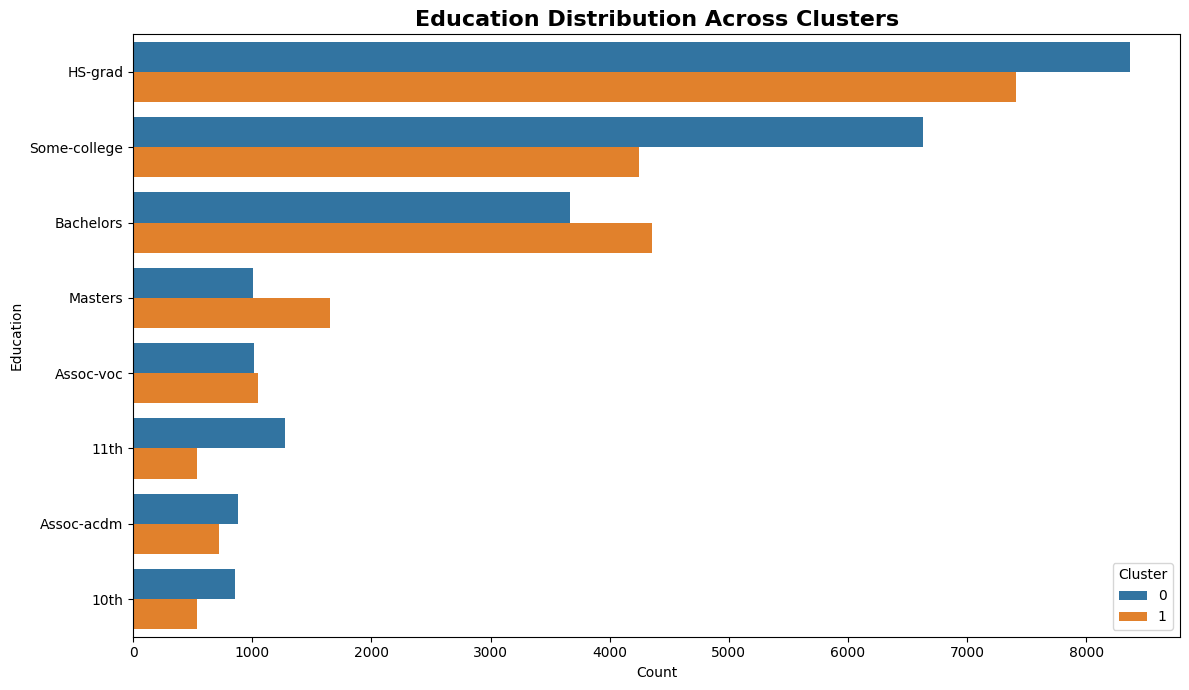

In [ ]:
top_education = adult['education'].value_counts().head(8).index

education_plot = adult[
    adult['education'].isin(top_education)
]

plt.figure(figsize=(12, 7))

sns.countplot(
    data=education_plot,
    y='education',
    hue='KMeans_Cluster',
    order=top_education
)

plt.title(
    'Education Distribution Across Clusters',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Count')
plt.ylabel('Education')
plt.legend(title='Cluster')

plt.tight_layout()
plt.show()

In [ ]:
occupation_dist = pd.crosstab(
    adult['occupation'],
    adult['KMeans_Cluster'],
    normalize='columns'
) * 100

occupation_dist.round(2)

KMeans_Cluster,0,1
occupation,,
Adm-clerical,15.19,6.18
Armed-Forces,0.03,0.03
Craft-repair,7.90,16.24
Exec-managerial,8.22,15.81
Farming-fishing,2.14,3.79
Handlers-cleaners,4.98,3.01
Machine-op-inspct,5.76,6.02
Other-service,14.22,4.34
Priv-house-serv,0.83,0.09


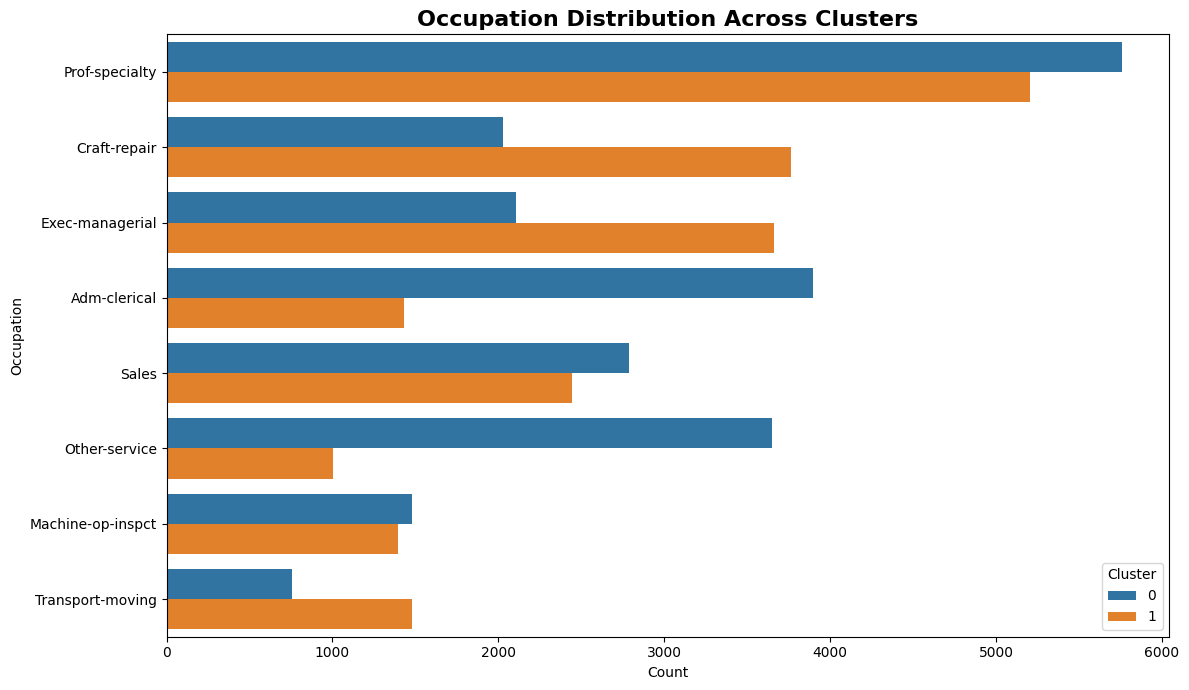

In [ ]:
top_occupations = adult['occupation'].value_counts().head(8).index

occupation_plot = adult[
    adult['occupation'].isin(top_occupations)
]

plt.figure(figsize=(12, 7))

sns.countplot(
    data=occupation_plot,
    y='occupation',
    hue='KMeans_Cluster',
    order=top_occupations
)

plt.title(
    'Occupation Distribution Across Clusters',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Count')
plt.ylabel('Occupation')
plt.legend(title='Cluster')

plt.tight_layout()
plt.show()

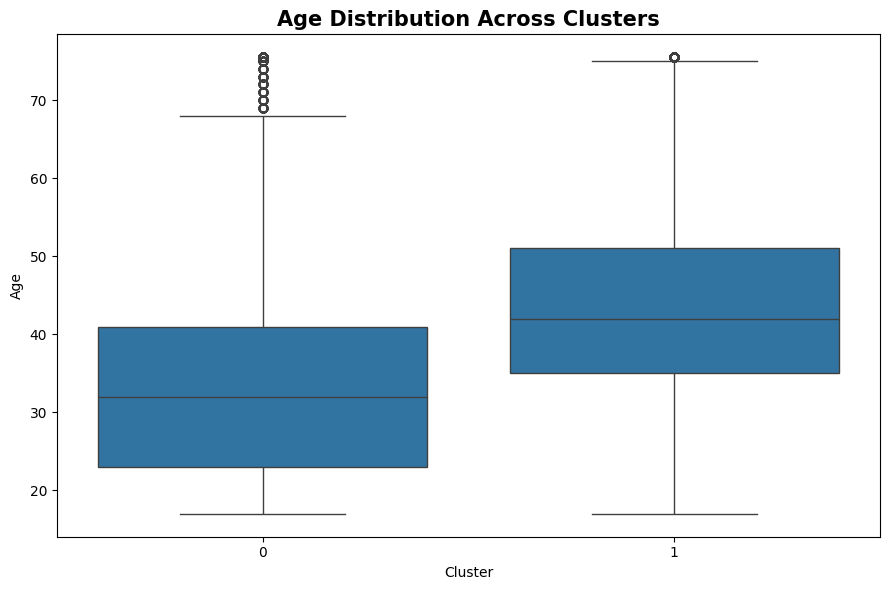

In [ ]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=adult,
    x='KMeans_Cluster',
    y='age'
)

plt.title(
    'Age Distribution Across Clusters',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Cluster')
plt.ylabel('Age')

plt.tight_layout()
plt.show()

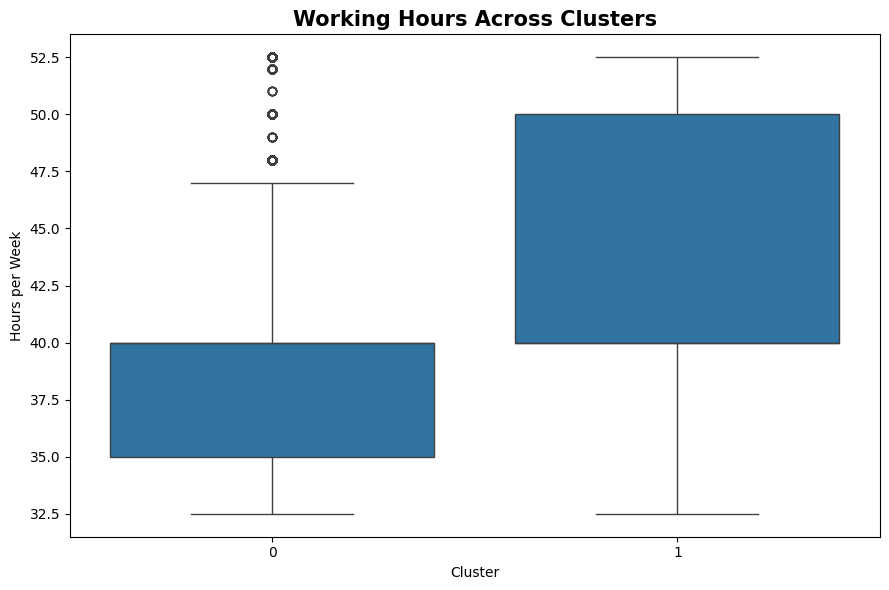

In [ ]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=adult,
    x='KMeans_Cluster',
    y='hours-per-week'
)

plt.title(
    'Working Hours Across Clusters',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Cluster')
plt.ylabel('Hours per Week')

plt.tight_layout()
plt.show()

# 4. Interpretation & Profiling

## Cluster 0

Cluster 0 contains the relatively younger group.

- Average age is around 34 years.
- Average working time is around 40 hours per week.
- Education level is slightly lower compared to Cluster 1.
- Capital gain is much lower.
- Around 94.63% of people earn <=50K.
- Only around 5.37% earn >50K.

From these observations, Cluster 0 can be considered as the relatively lower-income or economically weaker group.

## Cluster 1

Cluster 1 contains the relatively older group.

- Average age is around 43 years.
- Average working time is around 43 hours per week.
- Education level is slightly higher than Cluster 0.
- Capital gain is much higher.
- Around 55.50% earn <=50K.
- Around 44.50% earn >50K.

This cluster has a much higher percentage of higher-income people compared to Cluster 0.

So, Cluster 1 can be considered as the relatively better economic group.

### Comparison with Actual Income

The income column was not used while creating the clusters.

After clustering, income was used only to compare and understand the clusters.

- Cluster 0: 94.63% earn <=50K and 5.37% earn >50K.
- Cluster 1: 55.50% earn <=50K and 44.50% earn >50K.

This shows that the two clusters have different income patterns even though income was not used for training.

# 5. Policy Suggestions

### Upskilling Programs

Cluster 0 may benefit more from upskilling programs because most people in this cluster belong to the lower-income group.

Skill training, technical courses and job-oriented programs may help them get better job opportunities and improve their income.

### Tax Reform

Cluster 1 has more higher-income people and higher capital gains compared to Cluster 0.

Tax policies can consider the difference in income and economic condition of different groups. Higher-income groups can be considered differently from lower-income groups while making tax policies.

### Financial Aid and Inclusion

Cluster 0 may benefit more from financial aid and financial inclusion programs.

Possible support can include:

- Education assistance
- Skill development support
- Affordable loans
- Financial literacy
- Better access to banking services
- Employment support

These programs may help economically weaker people improve their financial condition.